# Reading the STL (stereolithography) format with `pyramids-mesh`

The **STL** (stereolithography) format is the lingua franca of 3D printing and CAD exchange: a bare triangle soup, each facet stored as a normal plus three vertices, in either ASCII or (as here) a compact binary layout. The sample is a **binary STL of a cube** — 12 triangles (two per cube face). `pyramids-mesh` reads it into a `pyramids.netcdf.ugrid` object, deduplicating the repeated vertices into a shared node table. This notebook reads it and explores what a closed 3D surface looks like inside a 2D mesh model.

## 1. Plotting backend and a figure helper

`pyramids-mesh` draws through **cleopatra** (reached via pyramids), which builds its own matplotlib figure. Under the non-interactive `Agg` backend nothing embeds on its own, so we define a tiny `show()` helper that grabs the current figure and displays it as an inline PNG. Call it right after every plot.

In [1]:
import os
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display


def show():
    """Render the current matplotlib figure inline as an embedded PNG."""
    from io import BytesIO

    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all")
    buf.seek(0)
    display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pathlib import Path

import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")
MESH = DATA / "stl" / "Cube.stl"
MESH.name, MESH.exists()

('Cube.stl', True)

`Cube.stl` lives in the `stl/` sub-folder (see `SOURCE.txt`), so the path is `DATA / "stl" / "Cube.stl"`. The tuple confirms it is found.

## 3. Read the file in one call

Like OFF, reading warns that some **clockwise faces were reversed** (winding normalisation) and some are **degenerate** — the cube's faces that stand perpendicular to the XY plane collapse to zero planar area when projected. The binary facets are parsed and their duplicated corner vertices merged into unique nodes.

In [3]:
ds = UgridDataset.read_file(MESH, driver="stl")
ds

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 2 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 8 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


UgridDataset(mesh='mesh2d', n_node=8, n_face=12, n_edge=0, variables=['node_z'])

A `UgridDataset` with the cube's merged nodes and its 12 triangular facets — the triangle soup is now a connected mesh object.

## 4. Explore the dataset

A handful of attributes describe what we loaded: node and face counts, the coordinate reference system, the names of any data variables, and the spatial extent.

In [4]:
import pandas as pd
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "data_variable_names": ds.data_variable_names,
    "bounds": ds.bounds,
}).to_frame("value")

,value
n_node,8
n_face,12
crs,None
epsg,None
data_variable_names,[node_z]
bounds,"(0.0, 0.0, 2.0, 2.0)"


**8 nodes, 12 faces**: the 12 facets reference only the cube's 8 unique corners (vertex deduplication at work). `crs`/`epsg` are `None` — STL has no georeferencing whatsoever. A `node_z` variable keeps the corners' heights.

## 5. A statistical summary of the fields

`summary()` returns a pandas frame with one row per data variable (count, min, max, mean, std).

In [5]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
node_z,8,0.0,2.0,1.0,1.0


The `node_z` row reflects the cube corners' elevations. No face field exists until we attach one.

## 6. The underlying `Mesh2d` geometry

`ds.mesh` is the `Mesh2d` object carrying the raw topology: node coordinates, the face-node connectivity table of shape `(n_face, k)` (row *i* lists the node indices of cell *i*), per-face areas, and cell centroids.

In [6]:
mesh = ds.mesh
fnc = np.asarray(mesh.face_node_connectivity.data)
areas = np.asarray(mesh.face_areas)
centroids = np.asarray(mesh.face_centroids)  # shape (2, n_face)
pd.Series({
    "connectivity_shape": fnc.shape,
    "nodes_per_face_k": fnc.shape[1],
    "area_min": float(areas.min()),
    "area_max": float(areas.max()),
    "centroids_shape": centroids.shape,
    "mesh_bounds": mesh.bounds,
}).to_frame("value")

,value
connectivity_shape,"(12, 3)"
nodes_per_face_k,3
area_min,0.0
area_max,2.0
centroids_shape,"(2, 12)"
mesh_bounds,"(0.0, 0.0, 2.0, 2.0)"


`k = 3` — STL is triangles only, by definition. The area range runs down to **0.0**: the four vertical cube faces (eight triangles) project to zero planar area, matching the degeneracy warning. Only the top/bottom triangles carry real 2D area.

## 7. The mesh outline (wireframe)

`plot_outline()` draws the bare cell edges, with no field attached — the quickest look at the raw geometry this driver produced.

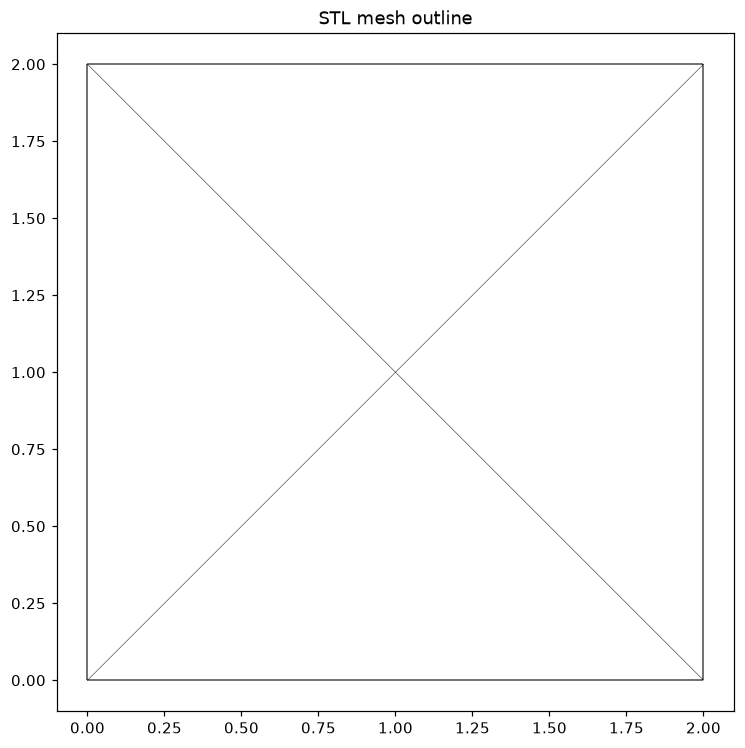

In [7]:
g = ds.plot_outline()
g.ax.set_title("STL mesh outline")
show()

The wireframe is the cube seen from directly above: its 12 triangles fold onto one another in plan view, so the outline reads as a square crossed by the facet diagonals.

## 8. A data map: attach and colour by cell area

These surface formats carry no field data, so there is nothing to colour by yet. We attach a derived **`cell_area`** variable at the face location and plot it — turning the geometry into a proper choropleth.

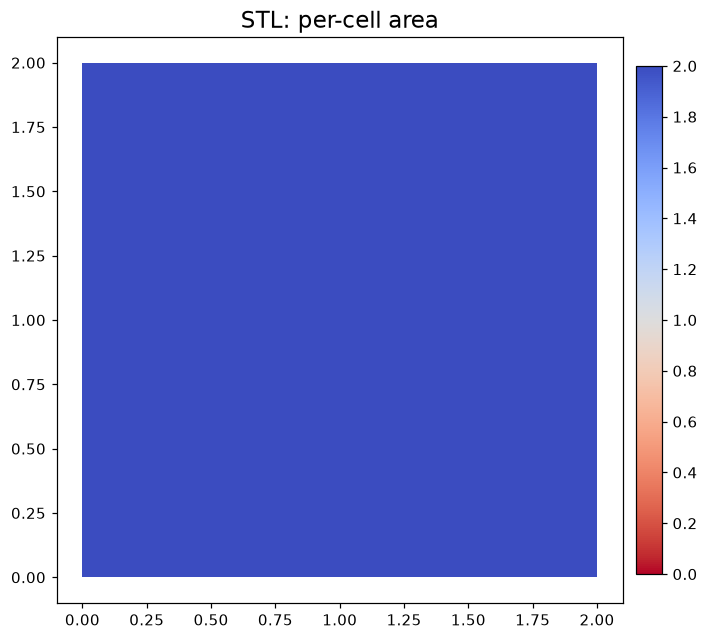

In [8]:
d2 = ds.with_variable("cell_area", np.asarray(mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True,
        title="STL: per-cell area")
show()

The `cell_area` map separates the horizontal facets (real area, brightly shaded) from the vertical ones (zero area, flat slivers) — a vivid reminder that STL is a full 3D surface being viewed in 2D projection.

## 9. GIS operations, for free

Because a `UgridDataset` is a first-class pyramids object, a whole GIS toolkit comes along. First, every face as a row in a GeoDataFrame.

In [9]:
gdf = ds.to_geodataframe()
print(gdf.shape, list(gdf.columns))
gdf.head()

(12, 1) ['geometry']


,geometry
0,"POLYGON ((0 2, 0 2, 0 0, 0 2))"
1,"POLYGON ((0 0, 0 0, 0 2, 0 0))"
2,"POLYGON ((2 2, 2 2, 0 2, 2 2))"
3,"POLYGON ((0 2, 0 2, 2 2, 0 2))"
4,"POLYGON ((2 0, 2 0, 2 2, 2 0))"


Twelve polygon rows, one per facet. The vertical faces appear as degenerate (zero-area) polygons — the 2D shadow of the cube's sides.

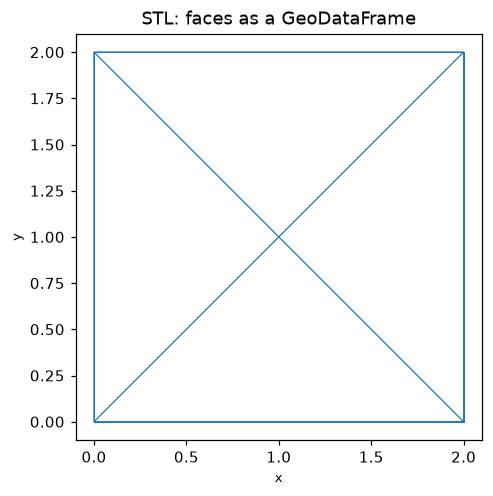

In [10]:
ax = gdf.boundary.plot(color="#1f77b4", linewidth=0.6)
ax.set_title("STL: faces as a GeoDataFrame")
ax.set_aspect("equal")
show()

The GeoDataFrame is the gateway to the entire shapely/geopandas ecosystem — spatial joins, buffering, reprojection, export to any OGR vector format — all on the mesh cells.

### Bounding polygon

`bounding_polygon()` returns a single shapely geometry: the dissolved outer footprint of the mesh.

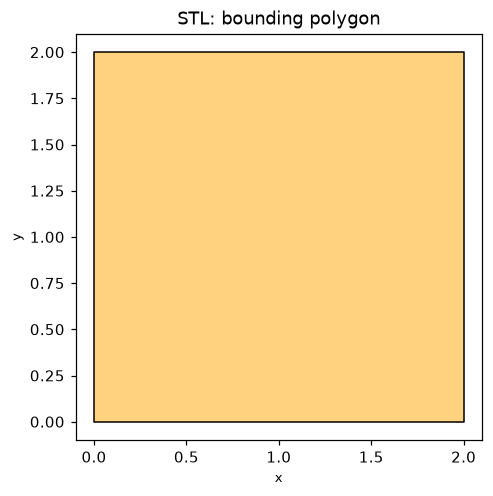

Polygon 4.0


In [11]:
import geopandas as gpd

poly = ds.bounding_polygon()
ax = gpd.GeoSeries([poly]).plot(facecolor="#ffd27f", edgecolor="k")
ax.set_title("STL: bounding polygon")
ax.set_aspect("equal")
show()
print(type(poly).__name__, round(poly.area, 4))

The bounding polygon is the square footprint the cube casts onto the plane.

### Derived topology and connectivity

A few more derived quantities are a method call away. `circumcenters()` is defined only for triangular meshes; `exterior_edges()` indexes the boundary edges; `connected_components()` labels disjoint pieces; `sparse_adjacency()` is the face-to-face graph as a sparse matrix.

In [12]:
try:
    cc = np.asarray(ds.circumcenters())
    circ = f"{cc.shape} array"
except ValueError as e:
    circ = f"skipped ({e})"
ext = np.asarray(ds.exterior_edges())
comp = np.asarray(ds.connected_components())
adj = ds.sparse_adjacency()
pd.Series({
    "circumcenters": circ,
    "n_boundary_edges": int(ext.size),
    "n_connected_components": int(np.unique(comp).size),
    "adjacency_shape": adj.shape,
    "adjacency_nnz": int(adj.nnz),
}).to_frame("value")

,value
circumcenters,"(12, 2) array"
n_boundary_edges,0
n_connected_components,1
adjacency_shape,"(12, 12)"
adjacency_nnz,36


Circumcenters are defined (triangular mesh). The boundary-edge count, connected-component label and sparse adjacency describe how the 12 facets stitch together into one closed surface.

### Cropping to a bounding box

`crop(bbox=...)` keeps the faces that fall within (or touch) a rectangle, returning a new `UgridDataset`. Here we crop to the left portion of the extent and redraw it.

faces: 12 -> 6


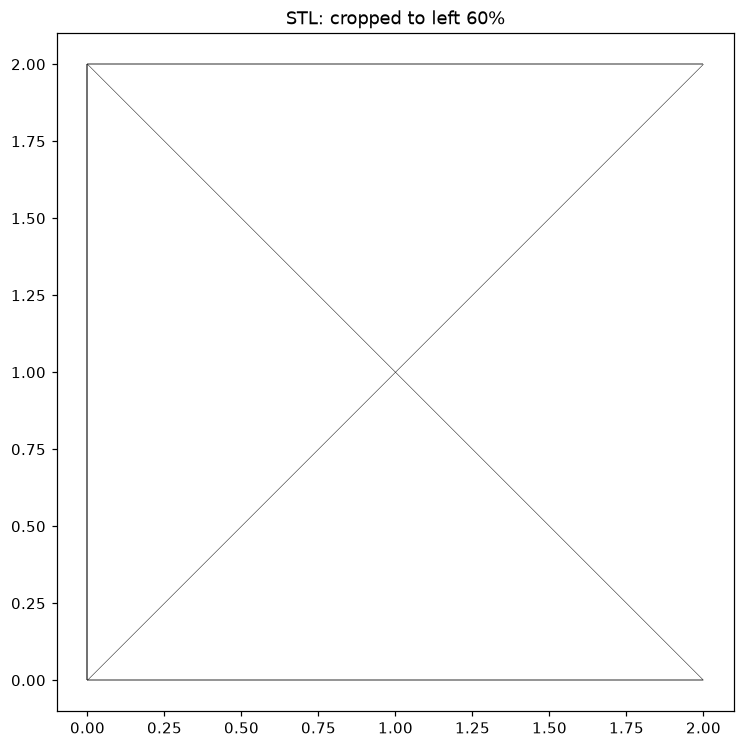

In [13]:
xmin, ymin, xmax, ymax = ds.bounds
bbox = (xmin, ymin, xmin + 0.6 * (xmax - xmin), ymax)
cropped = ds.crop(bbox=bbox)
print(f"faces: {ds.n_face} -> {cropped.n_face}")
gc = cropped.plot_outline()
gc.ax.set_title("STL: cropped to left 60%")
show()

Cropping to the left 60% keeps the facets intersecting the box — a sub-mesh of the cube's projected footprint.

### Round-tripping and the xarray view

`to_file(..., driver=...)` writes the mesh back out in any writable driver (here the solver-neutral 2DM), and `to_xarray()` exposes the whole dataset as an `xarray.Dataset` for NetCDF-style analysis.

In [14]:
import tempfile

out = Path(tempfile.gettempdir()) / "roundtrip.2dm"
ds.to_file(out, driver="2dm")
xds = ds.to_xarray()
print("wrote", out.name, "bytes:", out.stat().st_size)
print(xds.dims)

wrote roundtrip.2dm bytes: 334
FrozenMappingWarningOnValuesAccess({'mesh2d_scalar': 1, 'mesh2d_nNodes': 8, 'mesh2d_nFaces': 12, 'mesh2d_nMaxFaceNodes': 3})


The mesh survives the round-trip to a different format, and `to_xarray()` hands us a familiar labelled-array object — proof that a format-specific reader produces a fully generic, interoperable dataset.

## 10. What we skip here, and why

- **`to_crs(...)`** needs a source CRS to reproject from, but STL files carry no georeferencing (`crs=None`), so there is nothing to reproject. Attach a CRS first if the coordinates are known to be in a specific projection.
- **`rasterize_like(...)` / `regrid(...)`** require a *reference grid* (a raster or target mesh) to sample onto; with only this standalone mesh in hand there is no target, so they are out of scope for this tutorial.

## Takeaway

A binary STL triangle soup reads into a `UgridDataset` with its duplicate vertices merged into a shared node table. STL's job ends at parsing facets and normals; the resulting mesh behaves like any other — but because it is a genuine 3D surface, projecting it to the 2D plane produces zero-area vertical facets, a feature the geometry and area map make plain.